# IPL PROJECT 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv(r"C:\Users\Kalpesh\Desktop\Data Analysis\Project - python\IPL-Auction-Dataset.zip")
df.head()

,Unnamed: 0,Player's List,Base Price,TYPE,COST IN ₹ (CR.),Cost IN $ (000),2022 Squad,Team
0,0,Shivam Mavi,4000000,BOWLER,6.0,720.0,KKR,Gujarat Titans
1,1,Joshua Little,5000000,BOWLER,4.4,528.0,NaN,Gujarat Titans
2,2,Kane Williamson,20000000,BATSMAN,2.0,240.0,SRH,Gujarat Titans
3,3,K.S. Bharat,2000000,WICKETKEEPER,1.2,144.0,DC,Gujarat Titans
4,4,Mohit Sharma,5000000,BOWLER,0.5,60.0,NaN,Gujarat Titans


In [7]:
df.shape

(568, 8)

In [9]:
df.dtypes

Unnamed: 0           int64
Player's List          str
Base Price             str
TYPE                   str
COST IN ₹ (CR.)    float64
Cost IN $ (000)    float64
2022 Squad             str
Team                   str
dtype: object

In [10]:
# Detecting noisy data
unique_values = {}

for col in df.columns:
    unique_values[col] = df[col].unique()

print(unique_values)

{'Unnamed: 0': array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 17

In [11]:
# detecting null value check
df.isnull().sum()

Unnamed: 0           0
Player's List        0
Base Price           0
TYPE                 0
COST IN ₹ (CR.)    325
Cost IN $ (000)    325
2022 Squad         338
Team                 0
dtype: int64

In [12]:
df['Team'].value_counts()

Team
Unsold                        325
Gujarat Titans                 25
Chennai Super Kings            25
Delhi Capitals                 25
Lucknow Super Giants           25
Royal Challengers Banglore     25
Rajasthan Royals               25
Sunrisers Hyderabad            25
Mumbai Indians                 24
Kolkata Knight Riders          22
Punjab Super Kings             22
Name: count, dtype: int64

In [22]:
df['COST IN ₹ (CR.)'] = df['COST IN ₹ (CR.)'].fillna(df['COST IN ₹ (CR.)'].median())
df['Cost IN $ (000)'] = df['Cost IN $ (000)'].fillna(df['Cost IN $ (000)'].median())
df['2022 Squad'] = df['2022 Squad'].fillna(df['2022 Squad'].mode()[0])

In [23]:
## rechecking
df.isnull().sum()

Unnamed: 0         0
Player's List      0
Base Price         0
TYPE               0
COST IN ₹ (CR.)    0
Cost IN $ (000)    0
2022 Squad         0
Team               0
dtype: int64

In [ ]:
## 4. Detecting and handling Duplicates


In [24]:
df.duplicated().sum()

np.int64(0)

In [26]:
## Observation

In [27]:
df.describe()

,Unnamed: 0,COST IN ₹ (CR.),Cost IN $ (000)
count,568.000000,568.000000,568.000000
mean,283.500000,0.294014,35.281690
std,164.111751,1.675826,201.099179
min,0.000000,0.000000,0.000000
25%,141.750000,0.000000,0.000000
50%,283.500000,0.000000,0.000000
75%,425.250000,0.000000,0.000000
max,567.000000,18.500000,2220.000000


In [29]:
Q1=df['Cost IN $ (000)'].quantile(0.25)
Q1

np.float64(0.0)

In [31]:
Q3=df['Cost IN $ (000)'].quantile(0.75)
Q3

np.float64(0.0)

In [34]:
IQR=Q3-Q1
IQR

np.float64(0.0)

In [36]:
LB = Q1-1.5*IQR
UB = Q3+1.5*IQR
print(LB,UB)

0.0 0.0


In [38]:
non_zero = df[df['Cost IN $ (000)'] > 0]['Cost IN $ (000)']

Q1 = non_zero.quantile(0.25)
Q3 = non_zero.quantile(0.75)
IQR = Q3 - Q1

LB = Q1-1.5*IQR
UB = Q3+1.5*IQR
print(Q1, Q3, IQR, LB, UB)

outliers = df[(df['Cost IN $ (000)']<LB)|(df['Cost IN $ (000)']>UB)]
outliers

24.0 189.0 165.0 -223.5 436.5


,Unnamed: 0,Player's List,Base Price,TYPE,COST IN ₹ (CR.),Cost IN $ (000),2022 Squad,Team
0,0,Shivam Mavi,4000000,BOWLER,6.00,720.0,KKR,Gujarat Titans
1,1,Joshua Little,5000000,BOWLER,4.40,528.0,MI,Gujarat Titans
25,25,Ben Stokes,20000000,ALL-ROUNDER,16.25,1950.0,MI,Chennai Super Kings
50,50,Mukesh Kumar,2000000,BOWLER,5.50,660.0,MI,Delhi Capitals
51,51,Rilee Rossouw,20000000,BATSMAN,4.60,552.0,MI,Delhi Capitals
97,97,Sam Curran,20000000,ALL-ROUNDER,18.50,2220.0,MI,Punjab Super Kings
119,119,Nicholas Pooran,20000000,WICKETKEEPER,16.00,1920.0,SRH,Lucknow Super Giants
144,144,Cameron Green,20000000,ALL-ROUNDER,17.50,2100.0,MI,Mumbai Indians
193,193,Jason Holder,20000000,ALL-ROUNDER,5.75,690.0,LSG,Rajasthan Royals
218,218,Harry Brook,15000000,BATSMAN,13.25,1590.0,MI,Sunrisers Hyderabad


In [43]:
df.sort_values('Cost IN $ (000)', ascending = False)

,Unnamed: 0,Player's List,Base Price,TYPE,COST IN ₹ (CR.),Cost IN $ (000),2022 Squad,Team
97,97,Sam Curran,20000000,ALL-ROUNDER,18.50,2220.0,MI,Punjab Super Kings
144,144,Cameron Green,20000000,ALL-ROUNDER,17.50,2100.0,MI,Mumbai Indians
25,25,Ben Stokes,20000000,ALL-ROUNDER,16.25,1950.0,MI,Chennai Super Kings
119,119,Nicholas Pooran,20000000,WICKETKEEPER,16.00,1920.0,SRH,Lucknow Super Giants
218,218,Harry Brook,15000000,BATSMAN,13.25,1590.0,MI,Sunrisers Hyderabad
...,...,...,...,...,...,...,...,...
524,524,Khizar Dafedar,2000000,ALL-ROUNDER,0.00,0.0,MI,Unsold
523,523,Atharva Ankolekar,2000000,ALL-ROUNDER,0.00,0.0,MI,Unsold
522,522,Mohd. Wasim,2000000,BOWLER,0.00,0.0,MI,Unsold
521,521,Rajeev Singh,2000000,BOWLER,0.00,0.0,MI,Unsold


In [46]:
df_clean=df[(df['Cost IN $ (000)']<=LB)&(df['Cost IN $ (000)']>= UB)]
df_clean

,Unnamed: 0,Player's List,Base Price,TYPE,COST IN ₹ (CR.),Cost IN $ (000),2022 Squad,Team


## Data visualization

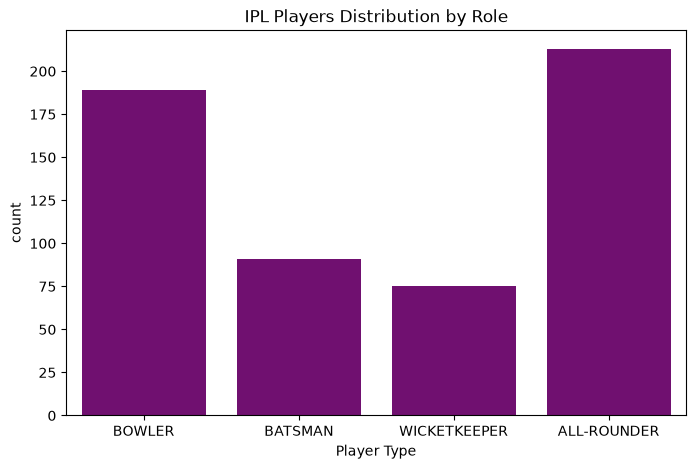

In [8]:
plt.figure(figsize = (8,5))
sns.countplot(x = 'TYPE', data = df,color = 'purple')
plt.title('IPL Players Distribution by Role')
plt.xlabel('Player Type')
plt.show()

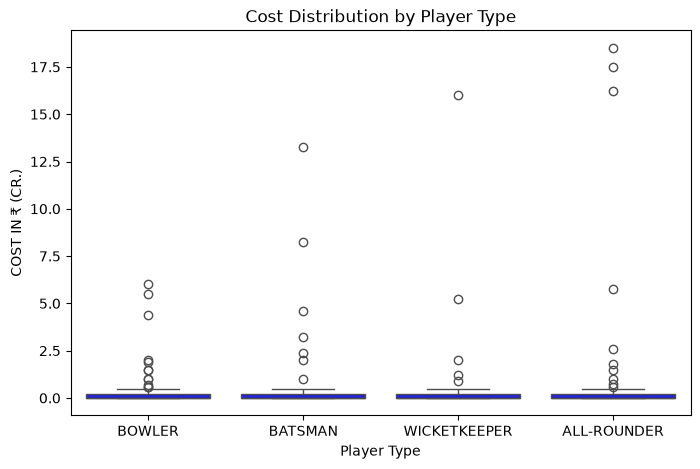

In [11]:
plt.figure(figsize = (8,5))
sns.boxplot(x='TYPE', y='COST IN ₹ (CR.)', data = df,color = 'blue')
plt.title('Cost Distribution by Player Type')
plt.xlabel('Player Type')
plt.ylabel('COST IN ₹ (CR.)')
plt.show()

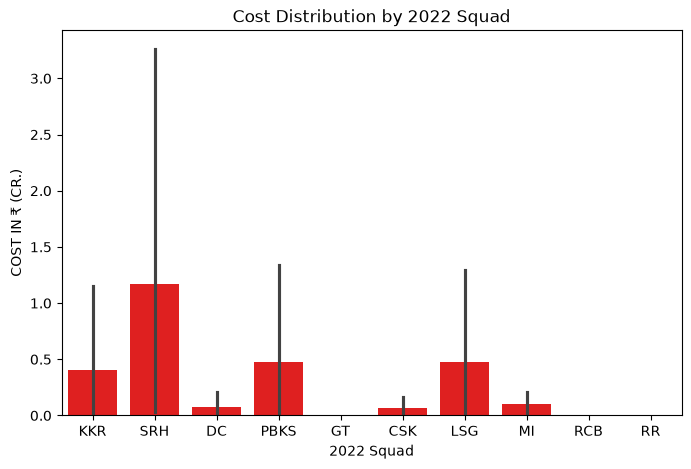

In [13]:
plt.figure(figsize = (8,5))
sns.barplot(x='2022 Squad', y='COST IN ₹ (CR.)', data = df,color = 'red')
plt.title('Cost Distribution by 2022 Squad')
plt.xlabel('2022 Squad')
plt.ylabel('COST IN ₹ (CR.)')
plt.show()

In [21]:
df[df['Base Price'] == 'Retained']

,Unnamed: 0,Player's List,Base Price,TYPE,COST IN ₹ (CR.),Cost IN $ (000),2022 Squad,Team
7,7,Rahul Tewatia,Retained,ALL-ROUNDER,0.0,0.0,GT,Gujarat Titans
8,8,Pradeep Sangwan,Retained,ALL-ROUNDER,0.0,0.0,GT,Gujarat Titans
9,9,Rashid Khan,Retained,BOWLER,0.0,0.0,GT,Gujarat Titans
10,10,R. Sai Kishore,Retained,BOWLER,0.0,0.0,GT,Gujarat Titans
11,11,Yash Dayal,Retained,BOWLER,0.0,0.0,GT,Gujarat Titans
...,...,...,...,...,...,...,...,...
238,238,Abdul Samad,Retained,BATSMAN,0.0,0.0,SRH,Sunrisers Hyderabad
239,239,Abhishek Sharma,Retained,ALL-ROUNDER,0.0,0.0,SRH,Sunrisers Hyderabad
240,240,Aiden Markram,Retained,BATSMAN,0.0,0.0,SRH,Sunrisers Hyderabad
241,241,Bhuvneshwar Kumar,Retained,BOWLER,0.0,0.0,SRH,Sunrisers Hyderabad


In [29]:
df_numeric = df[df['Base Price'] != 'Retained'].copy()
df_numeric ['Base Price'] = df_numeric['Base Price'].astype(float)

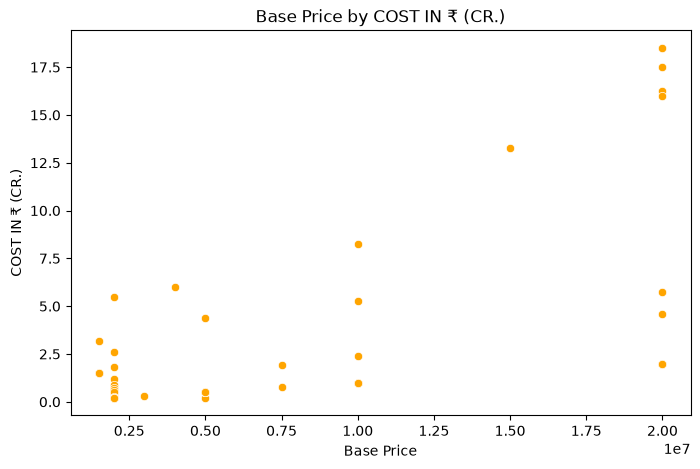

In [32]:
plt.figure(figsize = (8,5))
sns.scatterplot(x='Base Price', y='COST IN ₹ (CR.)', data = df_numeric,color = 'orange')
plt.title('Base Price by COST IN ₹ (CR.)')
plt.xlabel('Base Price')
plt.ylabel('COST IN ₹ (CR.)')
plt.show()

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

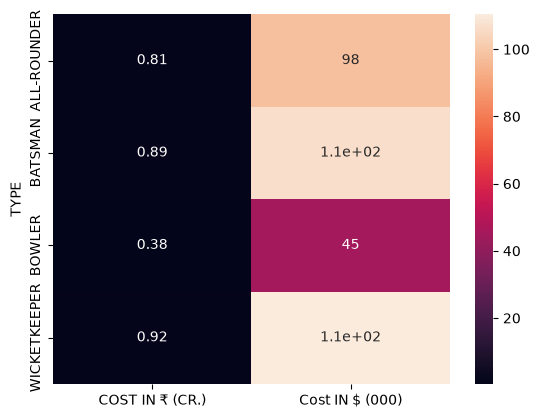

In [39]:
pivot = df.groupby('TYPE')[['COST IN ₹ (CR.)','Cost IN $ (000)']].mean()
sns.heatmap(pivot, annot = True)
plt.show()